   # Do variability classes differ in amplitude?
   Main sample (G <= 17, classifier score >= 0.5) from notebook 03. Amplitude measure: trimmed range in the G band, log10-transformed.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

c = pd.read_csv("../data/processed/classified_sample_flagged.csv")
m = c[c["main_sample"]].copy()
m = m[m["best_class_name"] != "CV"]          # CV has only 3 stars after the cuts

print(len(m), "stars (CV excluded)")
print("non-positive trimmed ranges:", (m["trimmed_range_mag_g_fov"] <= 0).sum())

m["log_amp"] = np.log10(m["trimmed_range_mag_g_fov"])

summary = m.groupby("best_class_name")["log_amp"].agg(["size", "mean", "std", "median"]).round(3)
print(summary)

2079 stars (CV excluded)
non-positive trimmed ranges: 0
                 size   mean    std  median
best_class_name                            
CEP                83 -0.294  0.167  -0.292
DSCT|GDOR|SXPHE   425 -1.575  0.240  -1.629
ECL               138 -0.643  0.361  -0.580
LPV               427 -0.581  0.346  -0.659
RR                231 -0.231  0.165  -0.215
RS                309 -0.982  0.178  -0.991
S                 160 -0.271  0.116  -0.273
SOLAR_LIKE        306 -1.580  0.137  -1.596


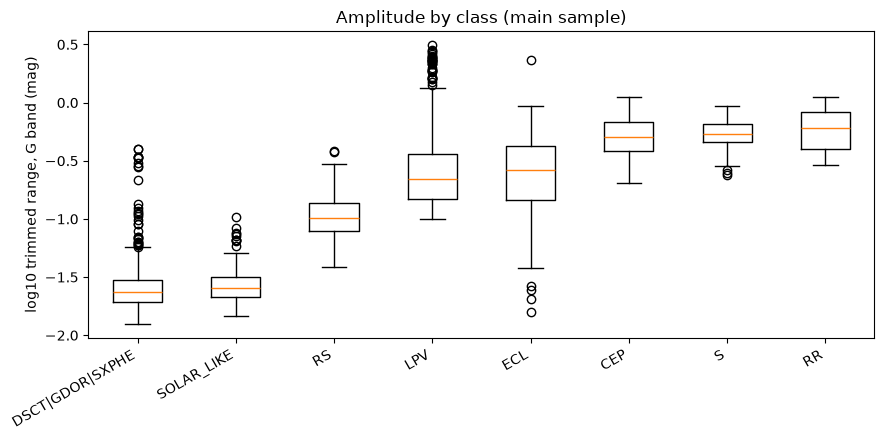

In [2]:
order = summary.sort_values("median").index
data = [m.loc[m["best_class_name"] == k, "log_amp"] for k in order]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(data)
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_ylabel("log10 trimmed range, G band (mag)")
ax.set_title("Amplitude by class (main sample)")
plt.tight_layout()
plt.show()